# 02_XGBoost — NASA C-MAPSS FD001

**Project:** Remaining Useful Life Prediction for Turbofan Engines Using XGBoost and LSTM  
**Dataset:** NASA C-MAPSS FD001

This notebook trains the XGBoost model.

I use:
- the same FD001 data from the EDA notebook
- an RUL cap of 125 cycles for training
- an engine-level train/validation split
- rolling and difference features made from past and current cycles only
- RMSE and MAE as the main error measures

## 1. Imports


In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

from xgboost import XGBRegressor
import xgboost

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("xgboost version:", xgboost.__version__)

xgboost version: 3.4.0


## 2. Settings

I use a fixed random seed so the same split can be reproduced.

The rolling windows are 5 and 10 cycles.


In [2]:
RANDOM_STATE = 42
RUL_CAP = 125
ROLL_WINDOWS = (5, 10)

np.random.seed(RANDOM_STATE)

OUTPUT_DIR = Path("xgboost_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Random seed:", RANDOM_STATE)
print("RUL cap:", RUL_CAP)
print("Rolling windows:", ROLL_WINDOWS)
print("Output directory:", OUTPUT_DIR.resolve())

Random seed: 42
RUL cap: 125
Rolling windows: (5, 10)
Output directory: C:\Users\ak587\Downloads\New folder\xgboost_outputs


## 3. Load the FD001 files

The notebook loads:

- `train_FD001.txt`
- `test_FD001.txt`
- `RUL_FD001.txt`


In [3]:
def resolve_file(filename):
    local = Path(filename)
    if local.exists():
        return local

    alt = Path("/mnt/data") / filename
    if alt.exists():
        return alt

    raise FileNotFoundError(
        f"{filename} was not found. Put it in the same folder as this notebook."
    )

TRAIN_PATH = resolve_file("train_FD001.txt")
TEST_PATH = resolve_file("test_FD001.txt")
RUL_PATH = resolve_file("RUL_FD001.txt")

columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(TRAIN_PATH, sep=r"\s+", header=None, names=columns)
test = pd.read_csv(TEST_PATH, sep=r"\s+", header=None, names=columns)
test_rul = pd.read_csv(RUL_PATH, sep=r"\s+", header=None, names=["RUL"])

print("Training shape:", train.shape)
print("Test shape:    ", test.shape)
print("RUL shape:     ", test_rul.shape)

Training shape: (20631, 26)
Test shape:     (13096, 26)
RUL shape:      (100, 1)


## 4. Create the training RUL

I calculate raw RUL as:

\[
RUL_{raw} = \text{last cycle of the engine} - \text{current cycle}
\]

For model training I cap RUL at 125 cycles.


In [4]:
train_model = train.copy()

max_cycle_per_engine = train_model.groupby("unit")["cycle"].transform("max")
train_model["RUL_raw"] = max_cycle_per_engine - train_model["cycle"]
train_model["RUL"] = train_model["RUL_raw"].clip(upper=RUL_CAP)

display(train_model[["unit", "cycle", "RUL_raw", "RUL"]].head(10))

,unit,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


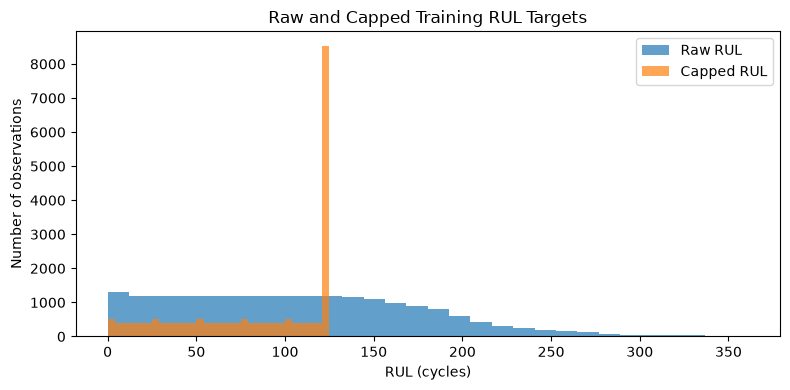

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(train_model["RUL_raw"], bins=30, alpha=0.7, label="Raw RUL")
plt.hist(train_model["RUL"], bins=30, alpha=0.7, label="Capped RUL")
plt.xlabel("RUL (cycles)")
plt.ylabel("Number of observations")
plt.title("Raw and Capped Training RUL Targets")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Remove constant columns

I remove the columns that were constant in the EDA notebook because they do not add information.


In [6]:
constant_columns = [
    col for col in columns
    if train_model[col].nunique(dropna=False) == 1
]

print("Constant columns:")
for col in constant_columns:
    print("-", col)

Constant columns:
- op_setting_3
- sensor_1
- sensor_5
- sensor_10
- sensor_16
- sensor_18
- sensor_19


## 6. Create time-based features

XGBoost does not read a full sequence in the same way as an LSTM.

For each useful sensor I add:
- the current value
- the change from the previous cycle
- rolling mean over 5 cycles
- rolling standard deviation over 5 cycles
- rolling mean over 10 cycles
- rolling standard deviation over 10 cycles

The calculations are done separately for each engine and do not use future cycles.


In [7]:
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]
informative_sensors = [c for c in sensor_columns if c not in constant_columns]

base_feature_columns = [
    "cycle",
    "op_setting_1",
    "op_setting_2",
] + informative_sensors

print("Number of informative sensors:", len(informative_sensors))
print("Base feature count:", len(base_feature_columns))

Number of informative sensors: 15
Base feature count: 18


In [8]:
def add_temporal_features(df, sensor_cols, windows=(5, 10)):
    """
    Create causal temporal features separately within each engine.
    Only the current and earlier cycles are used.
    """
    result = df.sort_values(["unit", "cycle"]).copy()

    grouped = result.groupby("unit", group_keys=False)

    for sensor in sensor_cols:
        # First difference
        result[f"{sensor}_diff1"] = grouped[sensor].diff().fillna(0.0)

        # Causal rolling statistics
        for w in windows:
            result[f"{sensor}_rollmean_{w}"] = (
                grouped[sensor]
                .rolling(window=w, min_periods=1)
                .mean()
                .reset_index(level=0, drop=True)
            )

            result[f"{sensor}_rollstd_{w}"] = (
                grouped[sensor]
                .rolling(window=w, min_periods=2)
                .std()
                .reset_index(level=0, drop=True)
                .fillna(0.0)
            )

    return result


train_feat = add_temporal_features(
    train_model,
    informative_sensors,
    windows=ROLL_WINDOWS
)

test_feat = add_temporal_features(
    test,
    informative_sensors,
    windows=ROLL_WINDOWS
)

print("Training feature table shape:", train_feat.shape)
print("Test feature table shape:    ", test_feat.shape)

Training feature table shape: (20631, 103)
Test feature table shape:     (13096, 101)


## 7. Final XGBoost features

This cell builds the final list of columns used by the model.


In [9]:
temporal_feature_columns = []

for sensor in informative_sensors:
    temporal_feature_columns.append(f"{sensor}_diff1")
    for w in ROLL_WINDOWS:
        temporal_feature_columns.append(f"{sensor}_rollmean_{w}")
        temporal_feature_columns.append(f"{sensor}_rollstd_{w}")

feature_columns = base_feature_columns + temporal_feature_columns

print("Total XGBoost feature count:", len(feature_columns))
print("Example features:")
print(feature_columns[:25])

Total XGBoost feature count: 93
Example features:
['cycle', 'op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'sensor_2_diff1', 'sensor_2_rollmean_5', 'sensor_2_rollstd_5', 'sensor_2_rollmean_10', 'sensor_2_rollstd_10', 'sensor_3_diff1', 'sensor_3_rollmean_5']


In [10]:
# Final sanity check before modelling
assert train_feat[feature_columns].isna().sum().sum() == 0
assert test_feat[feature_columns].isna().sum().sum() == 0

print("No missing values in engineered model features.")

No missing values in engineered model features.


## 8. Train and validation split

I split by engine instead of by row.

There are **80 training engines** and **20 validation engines**.

This avoids putting different cycles from the same engine in both groups.


In [11]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, val_idx = next(
    splitter.split(
        train_feat[feature_columns],
        train_feat["RUL"],
        groups=train_feat["unit"]
    )
)

fit_df = train_feat.iloc[train_idx].copy()
val_df = train_feat.iloc[val_idx].copy()

fit_engines = sorted(fit_df["unit"].unique())
val_engines = sorted(val_df["unit"].unique())

print("Training engines:", len(fit_engines))
print("Validation engines:", len(val_engines))
print("Overlap:", set(fit_engines).intersection(val_engines))
print("Validation engine IDs:", val_engines)

Training engines: 80
Validation engines: 20
Overlap: set()
Validation engine IDs: [np.int64(1), np.int64(5), np.int64(11), np.int64(13), np.int64(19), np.int64(23), np.int64(31), np.int64(32), np.int64(34), np.int64(40), np.int64(45), np.int64(46), np.int64(54), np.int64(71), np.int64(74), np.int64(77), np.int64(78), np.int64(81), np.int64(84), np.int64(91)]


## 9. Train XGBoost

I use a fixed model setup and early stopping.

The validation set is used to decide when training should stop.


In [12]:
xgb_params = {
    "n_estimators": 1500,
    "max_depth": 4,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 1,
    "reg_alpha": 0.0,
    "reg_lambda": 1.0,
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "early_stopping_rounds": 60,
}

model = XGBRegressor(**xgb_params)

start = time.time()

model.fit(
    fit_df[feature_columns],
    fit_df["RUL"],
    eval_set=[(val_df[feature_columns], val_df["RUL"])],
    verbose=False
)

training_seconds = time.time() - start

print(f"Training time: {training_seconds:.2f} seconds")
print("Best iteration:", getattr(model, "best_iteration", "not available"))
print("Best validation score:", getattr(model, "best_score", "not available"))

Training time: 0.79 seconds
Best iteration: 220
Best validation score: 14.611495833542424


## 10. Validation result

I report RMSE, MAE and R² on the held-out validation engines.


In [13]:
val_pred = model.predict(val_df[feature_columns])
val_pred = np.maximum(val_pred, 0)

val_rmse = np.sqrt(mean_squared_error(val_df["RUL"], val_pred))
val_mae = mean_absolute_error(val_df["RUL"], val_pred)
val_r2 = r2_score(val_df["RUL"], val_pred)

print(f"Validation RMSE: {val_rmse:.4f}")
print(f"Validation MAE:  {val_mae:.4f}")
print(f"Validation R²:   {val_r2:.4f}")

Validation RMSE: 14.6115
Validation MAE:  10.0839
Validation R²:   0.8773


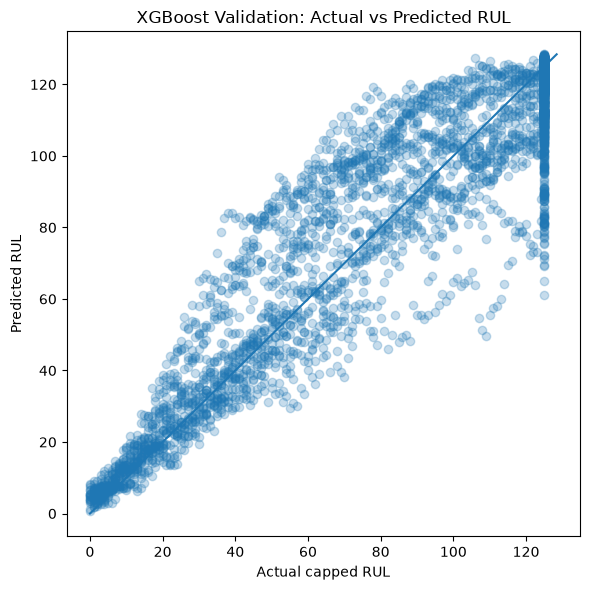

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(val_df["RUL"], val_pred, alpha=0.25)
minimum = min(val_df["RUL"].min(), val_pred.min())
maximum = max(val_df["RUL"].max(), val_pred.max())
plt.plot([minimum, maximum], [minimum, maximum])
plt.xlabel("Actual capped RUL")
plt.ylabel("Predicted RUL")
plt.title("XGBoost Validation: Actual vs Predicted RUL")
plt.tight_layout()
plt.show()

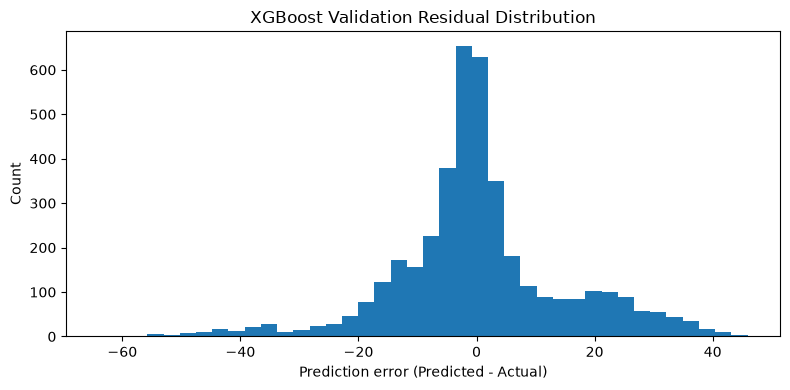

In [15]:
val_residuals = val_pred - val_df["RUL"].to_numpy()

plt.figure(figsize=(8, 4))
plt.hist(val_residuals, bins=40)
plt.xlabel("Prediction error (Predicted - Actual)")
plt.ylabel("Count")
plt.title("XGBoost Validation Residual Distribution")
plt.tight_layout()
plt.show()

## 11. Learning curve

This plot shows the validation RMSE during boosting.


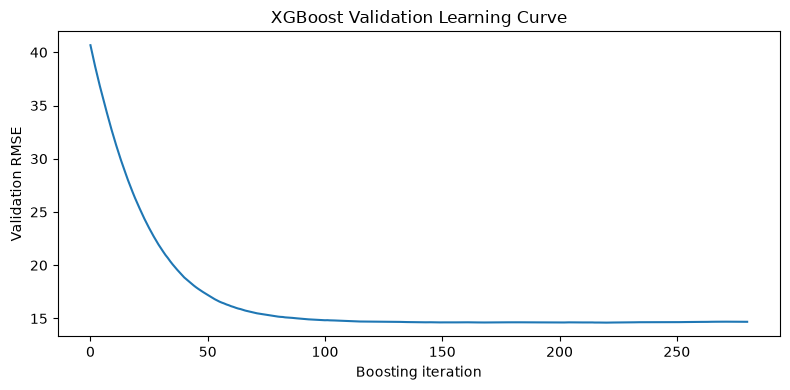

In [16]:
evals_result = model.evals_result()

if "validation_0" in evals_result and "rmse" in evals_result["validation_0"]:
    val_curve = evals_result["validation_0"]["rmse"]

    plt.figure(figsize=(8, 4))
    plt.plot(val_curve)
    plt.xlabel("Boosting iteration")
    plt.ylabel("Validation RMSE")
    plt.title("XGBoost Validation Learning Curve")
    plt.tight_layout()
    plt.show()
else:
    print("Evaluation history was not available in this XGBoost version.")

## 12. Official FD001 test result

For each of the 100 test engines I use the final observed cycle and its time-based features to predict RUL.

The prediction is then compared with the real value from `RUL_FD001.txt`.


In [17]:
test_last = (
    test_feat.loc[test_feat.groupby("unit")["cycle"].idxmax()]
    .sort_values("unit")
    .reset_index(drop=True)
)

assert len(test_last) == len(test_rul)

test_pred = model.predict(test_last[feature_columns])
test_pred = np.maximum(test_pred, 0)

test_actual = test_rul["RUL"].to_numpy()

test_rmse = np.sqrt(mean_squared_error(test_actual, test_pred))
test_mae = mean_absolute_error(test_actual, test_pred)
test_r2 = r2_score(test_actual, test_pred)

print(f"Official test RMSE: {test_rmse:.4f}")
print(f"Official test MAE:  {test_mae:.4f}")
print(f"Official test R²:   {test_r2:.4f}")

Official test RMSE: 18.4838
Official test MAE:  13.4419
Official test R²:   0.8022


## 13. NASA score

I also report the NASA asymmetric score.

This score gives a larger penalty to late predictions. RMSE and MAE are still my main comparison measures.


In [18]:
def nasa_score(y_true, y_pred):
    errors = np.asarray(y_pred) - np.asarray(y_true)

    score = np.where(
        errors < 0,
        np.exp(-errors / 13.0) - 1.0,
        np.exp(errors / 10.0) - 1.0
    )

    return float(np.sum(score))


test_nasa_score = nasa_score(test_actual, test_pred)

print(f"NASA asymmetric score: {test_nasa_score:.4f}")

NASA asymmetric score: 630.9485


## 14. Test prediction table

This table shows the real RUL, predicted RUL and error for each test engine.


In [19]:
prediction_table = pd.DataFrame({
    "unit": test_last["unit"].astype(int),
    "last_observed_cycle": test_last["cycle"].astype(int),
    "actual_RUL": test_actual,
    "predicted_RUL": test_pred,
})

prediction_table["error"] = (
    prediction_table["predicted_RUL"]
    - prediction_table["actual_RUL"]
)

prediction_table["absolute_error"] = prediction_table["error"].abs()

display(prediction_table.head(15))

,unit,last_observed_cycle,actual_RUL,predicted_RUL,error,absolute_error
0,1,31,112,122.898506,10.898506,10.898506
1,2,49,98,121.144669,23.144669,23.144669
2,3,126,69,54.785965,-14.214035,14.214035
3,4,106,82,81.621277,-0.378723,0.378723
4,5,98,91,94.916679,3.916679,3.916679
5,6,105,93,92.568039,-0.431961,0.431961
6,7,160,91,104.793213,13.793213,13.793213
7,8,166,95,79.761345,-15.238655,15.238655
8,9,55,111,120.020119,9.020119,9.020119
9,10,192,96,101.968369,5.968369,5.968369


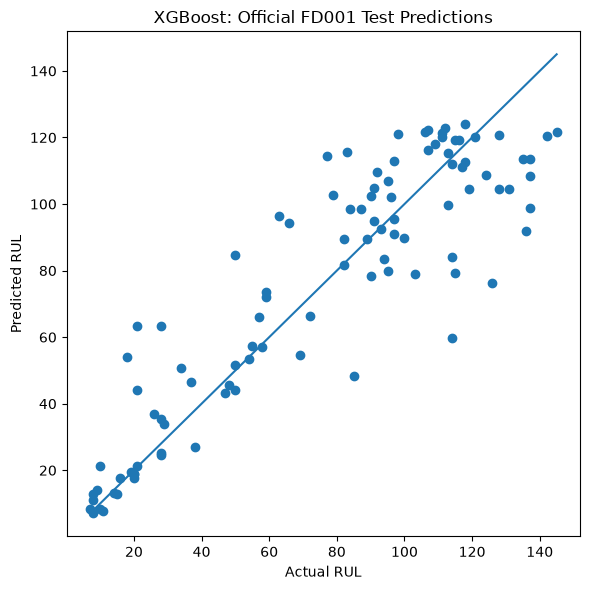

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(prediction_table["actual_RUL"], prediction_table["predicted_RUL"])
minimum = min(prediction_table["actual_RUL"].min(), prediction_table["predicted_RUL"].min())
maximum = max(prediction_table["actual_RUL"].max(), prediction_table["predicted_RUL"].max())
plt.plot([minimum, maximum], [minimum, maximum])
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("XGBoost: Official FD001 Test Predictions")
plt.tight_layout()
plt.show()

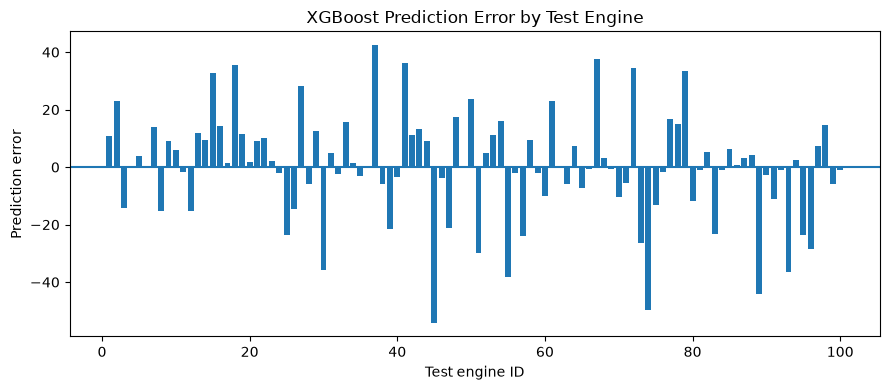

In [21]:
plt.figure(figsize=(9, 4))
plt.bar(prediction_table["unit"], prediction_table["error"])
plt.axhline(0)
plt.xlabel("Test engine ID")
plt.ylabel("Prediction error")
plt.title("XGBoost Prediction Error by Test Engine")
plt.tight_layout()
plt.show()

## 15. Largest errors

This table shows the engines where XGBoost made its biggest mistakes.


In [22]:
worst_errors = prediction_table.sort_values(
    "absolute_error",
    ascending=False
).head(15)

display(worst_errors)

,unit,last_observed_cycle,actual_RUL,predicted_RUL,error,absolute_error
44,45,152,114,59.893665,-54.106335,54.106335
73,74,137,126,76.231087,-49.768913,49.768913
88,89,177,136,91.813469,-44.186531,44.186531
36,37,121,21,63.402580,42.402580,42.402580
54,55,113,137,98.777161,-38.222839,38.222839
66,67,71,77,114.555412,37.555412,37.555412
92,93,244,85,48.399364,-36.600636,36.600636
40,41,123,18,54.149456,36.149456,36.149456
29,30,143,115,79.205879,-35.794121,35.794121
17,18,133,28,63.470387,35.470387,35.470387


## 16. Error by RUL range

I group the test engines by their real RUL to see where the model works well and where it struggles.


In [23]:
prediction_table["RUL_band"] = pd.cut(
    prediction_table["actual_RUL"],
    bins=[-np.inf, 30, 60, 90, 120, np.inf],
    labels=["0-30", "31-60", "61-90", "91-120", "121+"]
)

band_results = (
    prediction_table
    .groupby("RUL_band", observed=False)
    .agg(
        engines=("unit", "count"),
        MAE=("absolute_error", "mean"),
        mean_error=("error", "mean")
    )
    .reset_index()
)

display(band_results)

,RUL_band,engines,MAE,mean_error
0,0-30,25,8.300403,6.764054
1,31-60,14,9.000445,5.501998
2,61-90,15,18.061983,8.904315
3,91-120,33,12.605479,-1.246455
4,121+,13,24.904706,-24.904706


## 17. Feature importance

This shows the XGBoost feature-importance values.

I use it as a model summary, not as proof of cause and effect.


In [24]:
importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance.head(25))

,feature,importance
29,sensor_4_rollmean_5,0.240414
76,sensor_15_rollmean_10,0.133012
31,sensor_4_rollmean_10,0.123737
21,sensor_2_rollmean_10,0.094482
54,sensor_11_rollmean_5,0.091266
56,sensor_11_rollmean_10,0.035891
26,sensor_3_rollmean_10,0.033348
74,sensor_15_rollmean_5,0.025624
24,sensor_3_rollmean_5,0.020372
49,sensor_9_rollmean_5,0.018642


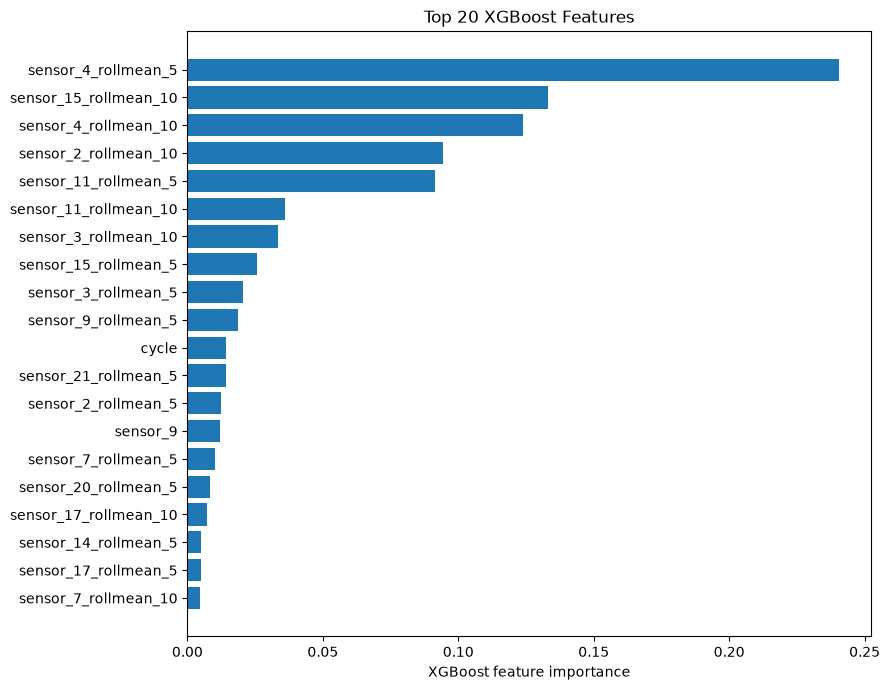

In [25]:
top_n = 20
top_importance = importance.head(top_n).sort_values("importance")

plt.figure(figsize=(9, 7))
plt.barh(top_importance["feature"], top_importance["importance"])
plt.xlabel("XGBoost feature importance")
plt.title(f"Top {top_n} XGBoost Features")
plt.tight_layout()
plt.show()

## 18. Save the model and results

The model, settings, metrics and prediction tables are saved in the output folder.


In [26]:
metrics = {
    "random_state": RANDOM_STATE,
    "rul_cap": RUL_CAP,
    "rolling_windows": list(ROLL_WINDOWS),
    "training_engines": len(fit_engines),
    "validation_engines": len(val_engines),
    "feature_count": len(feature_columns),
    "training_seconds": round(training_seconds, 4),
    "validation_rmse": round(float(val_rmse), 6),
    "validation_mae": round(float(val_mae), 6),
    "validation_r2": round(float(val_r2), 6),
    "test_rmse": round(float(test_rmse), 6),
    "test_mae": round(float(test_mae), 6),
    "test_r2": round(float(test_r2), 6),
    "test_nasa_score": round(float(test_nasa_score), 6),
    "best_iteration": (
        int(model.best_iteration)
        if getattr(model, "best_iteration", None) is not None
        else None
    ),
}

with open(OUTPUT_DIR / "xgboost_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

with open(OUTPUT_DIR / "xgboost_parameters.json", "w") as f:
    json.dump(xgb_params, f, indent=2)

prediction_table.to_csv(
    OUTPUT_DIR / "xgboost_test_predictions.csv",
    index=False
)

band_results.to_csv(
    OUTPUT_DIR / "xgboost_error_by_rul_band.csv",
    index=False
)

importance.to_csv(
    OUTPUT_DIR / "xgboost_feature_importance.csv",
    index=False
)

pd.DataFrame({
    "feature": feature_columns
}).to_csv(
    OUTPUT_DIR / "xgboost_feature_list.csv",
    index=False
)

pd.DataFrame({
    "training_engine": fit_engines
}).to_csv(
    OUTPUT_DIR / "training_engine_ids.csv",
    index=False
)

pd.DataFrame({
    "validation_engine": val_engines
}).to_csv(
    OUTPUT_DIR / "validation_engine_ids.csv",
    index=False
)

joblib.dump(
    model,
    OUTPUT_DIR / "xgboost_fd001_model.joblib"
)

print("Saved outputs to:", OUTPUT_DIR.resolve())
display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

Saved outputs to: C:\Users\ak587\Downloads\New folder\xgboost_outputs


,value
random_state,42
rul_cap,125
rolling_windows,"[5, 10]"
training_engines,80
validation_engines,20
feature_count,93
training_seconds,0.7855
validation_rmse,14.611496
validation_mae,10.083902
validation_r2,0.877315


## 19. Save the main figures

The main XGBoost figures are saved for later use.


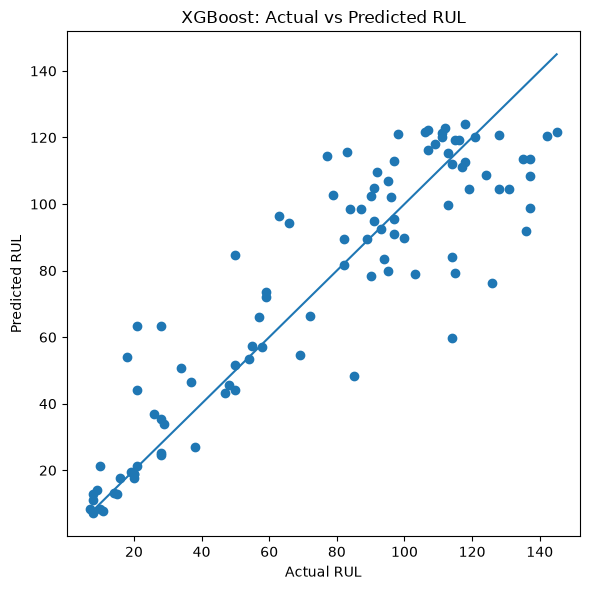

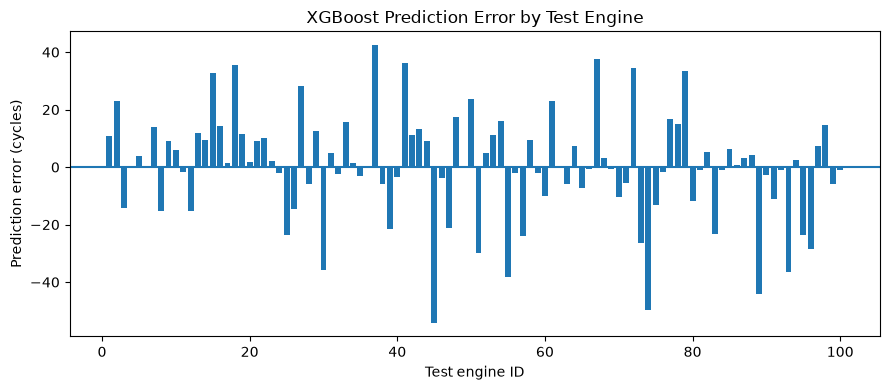

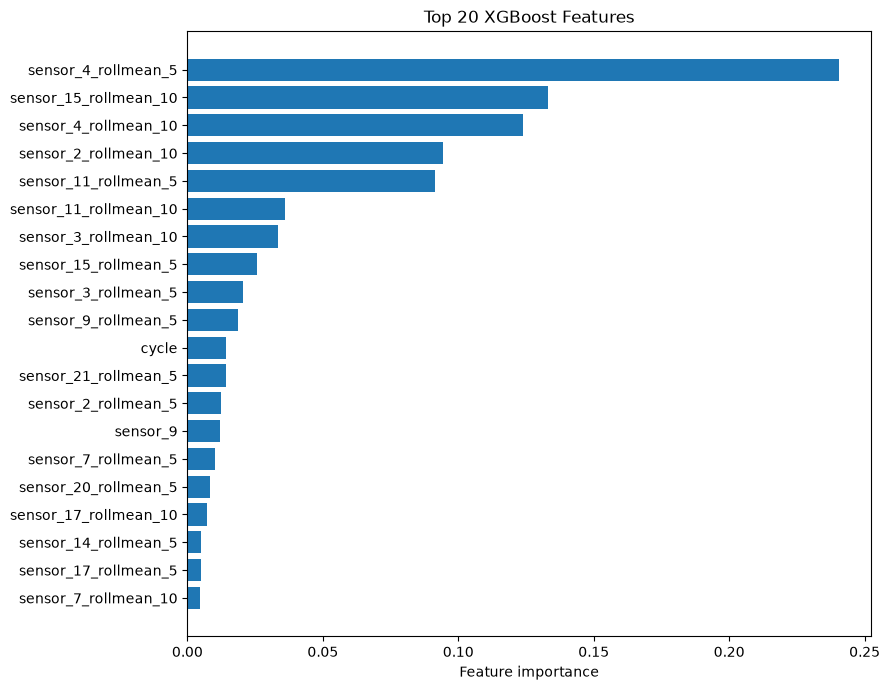

Figures saved.


In [27]:
# Actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(prediction_table["actual_RUL"], prediction_table["predicted_RUL"])
minimum = min(prediction_table["actual_RUL"].min(), prediction_table["predicted_RUL"].min())
maximum = max(prediction_table["actual_RUL"].max(), prediction_table["predicted_RUL"].max())
plt.plot([minimum, maximum], [minimum, maximum])
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("XGBoost: Actual vs Predicted RUL")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "xgboost_actual_vs_predicted.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Error by engine
plt.figure(figsize=(9, 4))
plt.bar(prediction_table["unit"], prediction_table["error"])
plt.axhline(0)
plt.xlabel("Test engine ID")
plt.ylabel("Prediction error (cycles)")
plt.title("XGBoost Prediction Error by Test Engine")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "xgboost_error_by_engine.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Feature importance
top_importance = importance.head(20).sort_values("importance")
plt.figure(figsize=(9, 7))
plt.barh(top_importance["feature"], top_importance["importance"])
plt.xlabel("Feature importance")
plt.title("Top 20 XGBoost Features")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "xgboost_top20_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Figures saved.")

## 20. XGBoost project log

### Data split

I used **80 engines for training** and **20 engines for validation**.

The validation engines were:

**1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84 and 91**

There was no overlap between the training and validation engine IDs.

### Features

I removed these constant columns:

- `op_setting_3`
- `sensor_1`
- `sensor_5`
- `sensor_10`
- `sensor_16`
- `sensor_18`
- `sensor_19`

That left **15 non-constant sensors**.

After adding the current values, first differences, rolling means and rolling standard deviations, the final XGBoost input had **93 features**.

I used rolling windows of **5 and 10 cycles**.

### Training

The best boosting iteration was **220**.

Training took about **0.79 seconds** on this run.

### Validation result

On the 20 validation engines:

- RMSE: **14.6115 cycles**
- MAE: **10.0839 cycles**
- R²: **0.8773**

### Official test result

On the 100 official FD001 test engines:

- RMSE: **18.4838 cycles**
- MAE: **13.4419 cycles**
- R²: **0.8022**
- NASA score: **630.9485**

The test error was higher than the validation error, so the official test set was harder for the model.

### Error by RUL range

| True RUL | Engines | MAE | Mean error |
|---|---:|---:|---:|
| 0-30 | 25 | 8.30 | +6.76 |
| 31-60 | 14 | 9.00 | +5.50 |
| 61-90 | 15 | 18.06 | +8.90 |
| 91-120 | 33 | 12.61 | -1.25 |
| 121+ | 13 | 24.90 | -24.90 |

The lowest MAE was in the **0-30** group.

The highest MAE was in the **121+** group. In that group the mean error was negative, so XGBoost usually predicted less remaining life than the real value.

### Biggest errors

The five largest absolute errors were:

- Engine 45: actual **114**, predicted **59.89**, absolute error **54.11**
- Engine 74: actual **126**, predicted **76.23**, absolute error **49.77**
- Engine 89: actual **136**, predicted **91.81**, absolute error **44.19**
- Engine 37: actual **21**, predicted **63.40**, absolute error **42.40**
- Engine 55: actual **137**, predicted **98.78**, absolute error **38.22**

### Most important features

The five highest feature-importance values were:

1. `sensor_4_rollmean_5`
2. `sensor_15_rollmean_10`
3. `sensor_4_rollmean_10`
4. `sensor_2_rollmean_10`
5. `sensor_11_rollmean_5`

Most of these are rolling features, so recent sensor history was useful for the XGBoost model.

### Main point from this model

XGBoost gave a good baseline, with test RMSE **18.4838** and MAE **13.4419**.

Its biggest weakness was on engines with high RUL.

The next notebook checks whether an LSTM can improve the result by using full 30-cycle sequences instead of hand-made rolling features.
